In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('output.csv')

In [3]:
import matplotlib.pyplot as plt

In [4]:
df.drop(['Filename'], axis =1, inplace=True)
df.head()

,Class,Width,Length,Area,diagonal,distance
0,drone,0.087500,0.100000,0.008750,0.132877,2.5
1,drone,0.682813,0.587500,0.401153,0.900772,1.0
2,drone,0.087500,0.089063,0.007793,0.124854,3.0
3,drone,0.121875,0.134375,0.016377,0.181412,2.0
4,drone,0.246875,0.207813,0.051304,0.322697,2.0


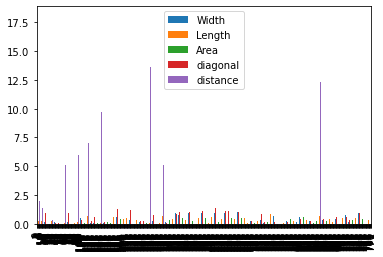

In [5]:
df.plot.bar()

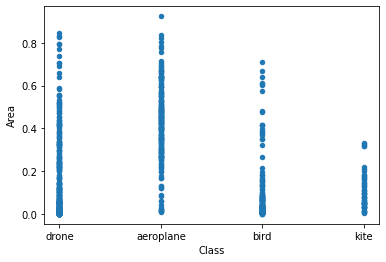

In [6]:
df.plot.scatter(x = 'Class', y = 'Area')

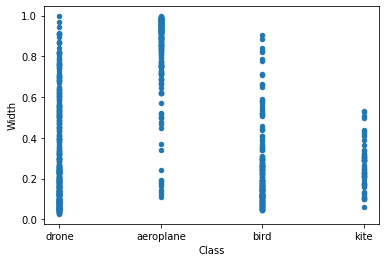

In [7]:
df.plot.scatter(x = 'Class', y = 'Width')

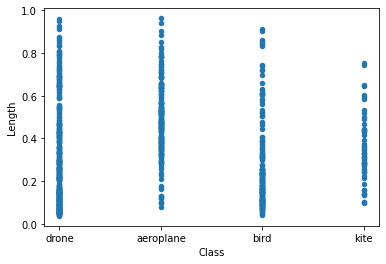

In [8]:
df.plot.scatter(x = 'Class', y = 'Length')

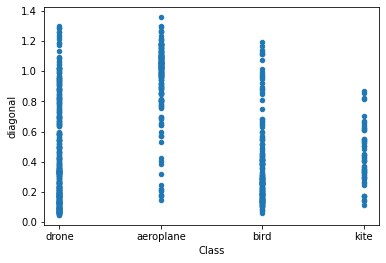

In [9]:
df.plot.scatter(x = 'Class', y = 'diagonal')

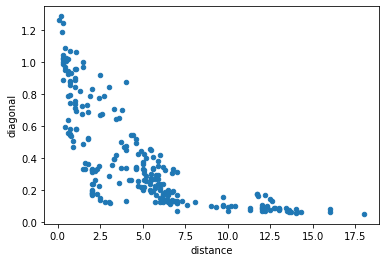

In [10]:
df.plot.scatter(x = 'distance', y = 'diagonal')

Conclusion from above graphs: 
1. dataset contains drone images at various distances with more datapoints
2. dataset does not contain far aeroplane images
3. very few datapoints for kite
4. Approximately it can be said that the diagonal and distance follow an inverse relation 


In [11]:
grouped = df.groupby(['Class'])
drone_df = grouped.get_group("drone")
drone_df        #(x - in_min) * (out_max - out_min) / (in_max - in_min) + out_min;

,Class,Width,Length,Area,diagonal,distance
0,drone,0.087500,0.100000,0.008750,0.132877,2.5
1,drone,0.682813,0.587500,0.401153,0.900772,1.0
2,drone,0.087500,0.089063,0.007793,0.124854,3.0
3,drone,0.121875,0.134375,0.016377,0.181412,2.0
4,drone,0.246875,0.207813,0.051304,0.322697,2.0
...,...,...,...,...,...,...
723,drone,0.360938,0.407813,0.147195,0.544599,4.3
724,drone,0.051562,0.048438,0.002498,0.070745,12.5
725,drone,0.668750,0.631250,0.422148,0.919621,2.5
726,drone,0.185938,0.267188,0.049680,0.325519,6.3


In [12]:
aero_df = grouped.get_group("aeroplane")
# aero_df

In [13]:
bird_df = grouped.get_group("bird")
# bird_df

In [14]:
kite_df = grouped.get_group("kite")
# kite_df

In [15]:
drone_df.isnull().sum()

Class        0
Width        0
Length       0
Area         0
diagonal     0
distance    96
dtype: int64

In [16]:
drone_df.shape

(343, 6)

In [17]:
drone_df.dropna(inplace = True)
drone_df.isnull().sum()

C:\Users\shrish shrinath vaid\AppData\Local\Temp\ipykernel_4696\3322683512.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drone_df.dropna(inplace = True)


Class       0
Width       0
Length      0
Area        0
diagonal    0
distance    0
dtype: int64

In [18]:
drone_df.shape

(247, 6)

In [19]:
drone_df['Width'] = drone_df['Width'].apply(lambda x: x*640)

C:\Users\shrish shrinath vaid\AppData\Local\Temp\ipykernel_4696\4064786449.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drone_df['Width'] = drone_df['Width'].apply(lambda x: x*640)


In [21]:
drone_df['Length'] = drone_df['Length'].apply(lambda x: x*640)

C:\Users\shrish shrinath vaid\AppData\Local\Temp\ipykernel_4696\210931393.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drone_df['Length'] = drone_df['Length'].apply(lambda x: x*640)


In [22]:
drone_df['diagonal'] = drone_df['diagonal'].apply(lambda x: x*640)

C:\Users\shrish shrinath vaid\AppData\Local\Temp\ipykernel_4696\228297260.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drone_df['diagonal'] = drone_df['diagonal'].apply(lambda x: x*640)


In [24]:
drone_df.drop(['Area'], axis=1, inplace = True)

C:\Users\shrish shrinath vaid\AppData\Local\Temp\ipykernel_4696\3235436223.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  drone_df.drop(['Area'], axis=1, inplace = True)


In [25]:
drone_df.head()

,Class,Width,Length,diagonal,distance
0,drone,56.00000,64.00000,85.041167,2.5
1,drone,437.00032,376.00000,576.493955,1.0
2,drone,56.00000,57.00032,79.906423,3.0
3,drone,78.00000,86.00000,116.103402,2.0
4,drone,158.00000,133.00032,206.526234,2.0


# Model Training

In [26]:
def display_scores(scores):
    print("Scores : ", scores)
    print("Mean : ", scores.mean())
    print("Std Deviation : ", scores.std())

In [27]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

In [28]:
y_train = drone_df['distance']

In [29]:
x_train = drone_df.drop(['distance', 'Class'], axis=1)
x_train.head()

,Width,Length,diagonal
0,56.00000,64.00000,85.041167
1,437.00032,376.00000,576.493955
2,56.00000,57.00032,79.906423
3,78.00000,86.00000,116.103402
4,158.00000,133.00032,206.526234


In [30]:
rf = RandomForestRegressor()

In [31]:
rf.fit(x_train, y_train)

RandomForestRegressor()

In [32]:
rf.predict(x_train)

array([ 3.859     ,  1.088     ,  3.996     ,  2.485     ,  2.727     ,
        4.68633333,  3.495     ,  2.168     ,  8.409     ,  1.665     ,
        0.65      ,  3.962     ,  1.806     ,  1.69      ,  5.735     ,
       12.396     ,  4.5       , 10.865     ,  5.023     ,  3.58945   ,
        0.614     , 13.965     , 11.856     ,  2.944     ,  3.75      ,
        0.364     ,  0.923     ,  3.484     ,  2.107     ,  2.561     ,
        2.56      ,  3.481     ,  1.583     ,  4.401     ,  2.917     ,
        0.989     ,  0.574     ,  6.5329    ,  9.765     ,  7.19      ,
        5.513     ,  6.296     ,  6.94508333, 10.258     , 10.678     ,
        5.431     ,  4.611     , 16.991     , 14.82      ,  0.342     ,
        7.736     ,  3.791     ,  1.694     ,  0.857     ,  0.881     ,
        1.34      ,  1.562     , 12.899     ,  2.867     ,  4.24366667,
        3.393     ,  3.018     ,  1.118     ,  3.9978    , 10.934     ,
        5.146     ,  4.368     , 15.36      ,  5.529     ,  5.07

In [26]:
y_train

0       2.5
1       1.0
2       3.0
3       2.0
4       2.0
       ... 
723     4.3
724    12.5
725     2.5
726     6.3
727     5.2
Name: distance, Length: 247, dtype: float64

In [33]:
scores = cross_val_score(rf, x_train, y_train, scoring="neg_mean_squared_error", cv=5)
rmse_scores = np.sqrt(-scores)
display_scores(rmse_scores)

Scores :  [2.30925812 2.11591179 1.7601424  2.58623298 1.65909399]
Mean :  2.086127854851502
Std Deviation :  0.3433376700935021


In [49]:
import math
from sklearn.metrics import mean_squared_error
math.sqrt(mean_squared_error(y_train, rf.predict(x_train)))

0.7130392696451524

## Hyperparameter tuning

In [39]:
bootstrap=['True', 'False']
n_estimators=[x for x in range(10, 100, 20)]
max_features=[2, 4, 6]
max_depth=[8, 11, 14, 20, 25]
min_samples_split=[2, 5]
min_samples_leaf=[1, 2]

In [40]:
param_grid={'n_estimators':n_estimators,
            'bootstrap': bootstrap,
            'max_features': max_features,
            'max_depth': max_depth,
            'min_samples_split': min_samples_split,
            'min_samples_leaf': min_samples_leaf
             }

In [41]:
grid_search= GridSearchCV(rf, param_grid, cv=5, scoring='neg_mean_squared_error', return_train_score=True, verbose=2)

In [42]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 600 candidates, totalling 3000 fits
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=1, min_samples_split=2, n_estimators=30; total time=   0.0s
[CV] END bootstrap=

[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.1s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.1s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.1s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.1s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.1s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_samples_split=2, n_estimators=90; total time=   0.2s
[CV] END bootstrap=True, max_depth=8, max_features=2, min_samples_leaf=2, min_sampl

[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_samples_split=5, n_estimators=50; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=1, min_sampl

[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=2, min_samples_split=5, n_estimators=90; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=2, min_samples_split=5, n_estimators=90; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=2, min_samples_split=5, n_estimators=90; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=2, min_samples_split=5, n_estimators=90; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=4, min_samples_leaf=2, min_samples_split=5, n_estimators=90; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=10; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=1, min_sampl

[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_samples_split=2, n_estimators=70; total time=   0.0s
[CV] END bootstrap=True, max_depth=8, max_features=6, min_samples_leaf=2, min_sampl

...

[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_leaf=2, min_samples_split=2, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=4, min_samples_l

[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=90; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=90; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=90; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=90; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=2, n_estimators=90; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=5, n_estimators=10; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=1, min_samples_split=5, n_estimators=10; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_l

[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=30; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=   0.0s
[CV] END bootstrap=False, max_depth=25, max_features=6, min_samples_l

C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\model_selection\_validation.py:372: FitFailedWarning: 
2000 fits failed out of a total of 3000.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2000 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\model_selection\_validation.py", line 680, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\ensemble\_forest.py", line 450, in fit
    trees = Parallel(
  File "C:\Users\shrish shrinath vaid\AppData\Local\

GridSearchCV(cv=5, estimator=RandomForestRegressor(),
             param_grid={'bootstrap': ['True', 'False'],
                         'max_depth': [8, 11, 14, 20, 25],
                         'max_features': [2, 4, 6], 'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [10, 30, 50, 70, 90]},
             return_train_score=True, scoring='neg_mean_squared_error',
             verbose=2)

In [43]:
grid_search.best_estimator_

RandomForestRegressor(bootstrap='True', max_depth=8, max_features=2,
                      min_samples_split=5, n_estimators=30)

In [44]:
rf_grid = grid_search.best_estimator_

In [45]:
scores = cross_val_score(rf_grid, x_train, y_train, scoring="neg_mean_squared_error", cv=5)
rmse_scores = np.sqrt(-scores)
display_scores(rmse_scores)

Scores :  [2.29831117 1.94234459 1.71217945 2.47384823 1.62495045]
Mean :  2.0103267770612616
Std Deviation :  0.3285773773522838


In [46]:
rf_grid.predict(x_train)

array([ 4.53835979,  1.06640019,  4.84412637,  2.86484474,  2.97039163,
        5.12892105,  3.74257978,  2.5136483 , 10.32936111,  1.89729326,
        0.57974868,  4.31192381,  1.86365873,  1.95169048,  5.30815546,
       13.01011833,  3.8715011 , 11.01855556,  4.95960476,  4.45735114,
        0.61235185, 13.88594841, 11.74505556,  3.5653188 ,  4.689845  ,
        0.33195022,  1.12242685,  3.93987093,  2.83038745,  3.25706696,
        2.3360463 ,  4.81350588,  1.47567521,  5.44627188,  3.02633474,
        1.09976018,  0.50252249,  6.5655642 , 10.60691667,  6.93009066,
        5.28496122,  5.5965126 ,  6.45084392, 10.72916667, 11.07634259,
        4.8893298 ,  4.67678143, 16.21440476, 13.79409524,  0.31630159,
        7.56306024,  3.31590948,  2.02888095,  1.07658823,  0.80398016,
        1.35534127,  1.85960285, 12.84083658,  3.6540668 ,  4.44550733,
        4.64978098,  4.06842176,  1.27190542,  4.43819876, 10.87757214,
        4.88716633,  4.75039574, 15.08019841,  5.09121587,  4.92

In [47]:
from sklearn.metrics import mean_squared_error
import math

In [48]:
math.sqrt(mean_squared_error(y_train, rf_grid.predict(x_train)))

1.0233120538625855

## Polynomial Regression

In [28]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [29]:
poly = PolynomialFeatures(degree = 3)

In [30]:
x_poly = poly.fit_transform(x_train)

In [31]:
poly_lr = LinearRegression()

In [32]:
poly_lr.fit(x_poly, y_train)

LinearRegression()

In [33]:
scores = cross_val_score(poly_lr, x_train, y_train, scoring="neg_mean_squared_error", cv=5)
rmse_scores = np.sqrt(-scores)
display_scores(rmse_scores)

Scores :  [3.14364362 2.50776817 2.01757953 2.54289109 2.25518804]
Mean :  2.493414091390478
Std Deviation :  0.3764631799913397


## SVM Regressor

In [34]:
from sklearn.svm import SVR
svr=SVR()
svr.fit(x_train, y_train)

SVR()

In [35]:
scores=cross_val_score(svr, x_train, y_train, cv=5, scoring='neg_mean_squared_error')
rmse_scores=np.sqrt(-scores)
display_scores(rmse_scores)

Scores :  [3.04547139 2.3811651  2.44031    2.64289611 2.43360919]
Mean :  2.588690358239893
Std Deviation :  0.24524306359046832


## HYperparameter

In [47]:
kernel=['poly', 'rbf', 'sigmoid']
degree=[i for i in range(1, 5)]
gamma=['scale', 'auto']
epsilon=[0.01, 0.05, 0.008]
C=[i for i in range(100, 200, 20)]

In [48]:
param_grid={'kernel': kernel, 'degree': degree, 'epsilon': epsilon, 'C': C }

In [49]:
grid=GridSearchCV(svr, param_grid, cv=5, verbose=2, return_train_score=True, scoring='neg_mean_squared_error')

In [50]:
grid.fit(x_train, y_train)


Fitting 5 folds for each of 180 candidates, totalling 900 fits
[CV] END .........C=100, degree=1, epsilon=0.01, kernel=poly; total time=   0.0s
[CV] END .........C=100, degree=1, epsilon=0.01, kernel=poly; total time=   0.0s
[CV] END .........C=100, degree=1, epsilon=0.01, kernel=poly; total time=   0.0s
[CV] END .........C=100, degree=1, epsilon=0.01, kernel=poly; total time=   0.0s
[CV] END .........C=100, degree=1, epsilon=0.01, kernel=poly; total time=   0.0s
[CV] END ..........C=100, degree=1, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=1, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=1, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=1, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=1, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ......C=100, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=100, degree=1, epsilon=0.01, 

[CV] END ......C=100, degree=3, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=100, degree=3, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=100, degree=3, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=100, degree=3, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END .........C=100, degree=3, epsilon=0.05, kernel=poly; total time=   0.6s
[CV] END .........C=100, degree=3, epsilon=0.05, kernel=poly; total time=   0.7s
[CV] END .........C=100, degree=3, epsilon=0.05, kernel=poly; total time=   1.3s
[CV] END .........C=100, degree=3, epsilon=0.05, kernel=poly; total time=   1.1s
[CV] END .........C=100, degree=3, epsilon=0.05, kernel=poly; total time=   2.0s
[CV] END ..........C=100, degree=3, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=3, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, degree=3, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=100, de

[CV] END ......C=120, degree=1, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=120, degree=1, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=120, degree=1, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ........C=120, degree=1, epsilon=0.008, kernel=poly; total time=   0.0s
[CV] END ........C=120, degree=1, epsilon=0.008, kernel=poly; total time=   0.0s
[CV] END ........C=120, degree=1, epsilon=0.008, kernel=poly; total time=   0.0s
[CV] END ........C=120, degree=1, epsilon=0.008, kernel=poly; total time=   0.0s
[CV] END ........C=120, degree=1, epsilon=0.008, kernel=poly; total time=   0.0s
[CV] END .........C=120, degree=1, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=120, degree=1, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=120, degree=1, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=120, degree=1, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=120, deg

[CV] END .........C=120, degree=3, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .....C=120, degree=3, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=120, degree=3, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=120, degree=3, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=120, degree=3, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=120, degree=3, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .........C=120, degree=4, epsilon=0.01, kernel=poly; total time=  34.8s
[CV] END .........C=120, degree=4, epsilon=0.01, kernel=poly; total time=  41.8s
[CV] END .........C=120, degree=4, epsilon=0.01, kernel=poly; total time=  29.0s
[CV] END .........C=120, degree=4, epsilon=0.01, kernel=poly; total time=  10.1s
[CV] END .........C=120, degree=4, epsilon=0.01, kernel=poly; total time=  26.2s
[CV] END ..........C=120, degree=4, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=120, de

[CV] END ..........C=140, degree=2, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ......C=140, degree=2, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=2, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=2, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=2, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=2, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END .........C=140, degree=2, epsilon=0.05, kernel=poly; total time=   0.1s
[CV] END .........C=140, degree=2, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END .........C=140, degree=2, epsilon=0.05, kernel=poly; total time=   0.2s
[CV] END .........C=140, degree=2, epsilon=0.05, kernel=poly; total time=   0.1s
[CV] END .........C=140, degree=2, epsilon=0.05, kernel=poly; total time=   0.1s
[CV] END ..........C=140, degree=2, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=140, de

[CV] END ......C=140, degree=4, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=4, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=4, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=4, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=140, degree=4, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ........C=140, degree=4, epsilon=0.008, kernel=poly; total time=  40.6s
[CV] END ........C=140, degree=4, epsilon=0.008, kernel=poly; total time=  16.6s
[CV] END ........C=140, degree=4, epsilon=0.008, kernel=poly; total time=  41.0s
[CV] END ........C=140, degree=4, epsilon=0.008, kernel=poly; total time=   5.9s
[CV] END ........C=140, degree=4, epsilon=0.008, kernel=poly; total time=  26.1s
[CV] END .........C=140, degree=4, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=140, degree=4, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=140, deg

[CV] END .....C=160, degree=2, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=160, degree=2, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=160, degree=2, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=160, degree=2, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .....C=160, degree=2, epsilon=0.008, kernel=sigmoid; total time=   0.0s
[CV] END .........C=160, degree=3, epsilon=0.01, kernel=poly; total time=   2.8s
[CV] END .........C=160, degree=3, epsilon=0.01, kernel=poly; total time=   2.9s
[CV] END .........C=160, degree=3, epsilon=0.01, kernel=poly; total time=   4.3s
[CV] END .........C=160, degree=3, epsilon=0.01, kernel=poly; total time=   1.4s
[CV] END .........C=160, degree=3, epsilon=0.01, kernel=poly; total time=   4.3s
[CV] END ..........C=160, degree=3, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=160, degree=3, epsilon=0.01, kernel=rbf; total time=   0.0s
[CV] END ..........C=160, de

[CV] END ......C=180, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=1, epsilon=0.01, kernel=sigmoid; total time=   0.0s
[CV] END .........C=180, degree=1, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END .........C=180, degree=1, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END .........C=180, degree=1, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END .........C=180, degree=1, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END .........C=180, degree=1, epsilon=0.05, kernel=poly; total time=   0.0s
[CV] END ..........C=180, degree=1, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=180, degree=1, epsilon=0.05, kernel=rbf; total time=   0.0s
[CV] END ..........C=180, de

[CV] END ......C=180, degree=3, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=3, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=3, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=3, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ......C=180, degree=3, epsilon=0.05, kernel=sigmoid; total time=   0.0s
[CV] END ........C=180, degree=3, epsilon=0.008, kernel=poly; total time=   0.7s
[CV] END ........C=180, degree=3, epsilon=0.008, kernel=poly; total time=   4.6s
[CV] END ........C=180, degree=3, epsilon=0.008, kernel=poly; total time=   2.9s
[CV] END ........C=180, degree=3, epsilon=0.008, kernel=poly; total time=   1.9s
[CV] END ........C=180, degree=3, epsilon=0.008, kernel=poly; total time=  11.4s
[CV] END .........C=180, degree=3, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=180, degree=3, epsilon=0.008, kernel=rbf; total time=   0.0s
[CV] END .........C=180, deg

GridSearchCV(cv=5, estimator=SVR(),
             param_grid={'C': [100, 120, 140, 160, 180], 'degree': [1, 2, 3, 4],
                         'epsilon': [0.01, 0.05, 0.008],
                         'kernel': ['poly', 'rbf', 'sigmoid']},
             return_train_score=True, scoring='neg_mean_squared_error',
             verbose=2)

In [76]:
grid.best_estimator_

SVR(C=140, degree=1, epsilon=0.008)

In [77]:
svr_grid = grid.best_estimator_
scores=cross_val_score(svr_grid, x_train, y_train, cv=5, scoring='neg_mean_squared_error')
rmse_scores=np.sqrt(-scores)
display_scores(rmse_scores)

Scores :  [2.55019527 1.96422868 1.48767065 2.32093666 1.51744356]
Mean :  1.96809496453527
Std Deviation :  0.4236147297077428


In [78]:
math.sqrt(mean_squared_error(y_train, svr_grid.predict(x_train)))

1.85928350827663

## Decision Tree

In [36]:
from sklearn.tree import DecisionTreeRegressor
dtr=DecisionTreeRegressor(max_depth=3)

In [37]:
dtr.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=3)

In [38]:
scores=cross_val_score(dtr, x_train, y_train, cv=10, scoring='neg_mean_squared_error')
rmse_scores=np.sqrt(-scores)
display_scores(scores)

Scores :  [-5.69705583 -4.71440746 -3.59120007 -3.22766728 -1.58659507 -5.73672123
 -8.77472541 -2.1637899  -2.10337309 -2.49325757]
Mean :  -4.008879291576442
Std Deviation :  2.1220524014709112


## Adaboost

In [39]:
from sklearn.ensemble import AdaBoostRegressor

In [40]:
ada_regressor=AdaBoostRegressor(DecisionTreeRegressor(max_depth=2), n_estimators=200, learning_rate=0.6, loss='exponential', random_state=40)

In [41]:
ada_regressor.fit(x_train, y_train)

AdaBoostRegressor(base_estimator=DecisionTreeRegressor(max_depth=2),
                  learning_rate=0.6, loss='exponential', n_estimators=200,
                  random_state=40)

In [42]:
scores= cross_val_score(ada_regressor, x_train, y_train, scoring='neg_mean_squared_error', cv=10)
rmse_scores=np.sqrt(-scores)
display_scores(scores)

Scores :  [-8.00428624 -5.37368373 -4.28198578 -3.22954323 -1.71406086 -4.7448564
 -7.09974929 -1.80540178 -1.91235248 -2.07141977]
Mean :  -4.023733956308595
Std Deviation :  2.1649834086335598


## SGDRegressor

In [43]:
from sklearn.linear_model import SGDRegressor

In [44]:
sgdr = SGDRegressor()

In [45]:
sgdr.fit(x_train, y_train)

SGDRegressor()

In [46]:
scores= cross_val_score(sgdr, x_train, y_train, scoring='neg_mean_squared_error', cv=10)
rmse_scores=np.sqrt(-scores)
display_scores(scores)

Scores :  [-11.33704749 -12.64902523 -10.78297606  -5.70033452  -4.7796247
 -12.0740965   -5.00233755  -6.16113795  -7.13748774  -7.25547686]
Mean :  -8.287954459210017
Std Deviation :  2.9255474054102497


## Final

In [50]:
final_model = rf

final_model

RandomForestRegressor()

In [52]:
final_model.predict([[212.73353576660156 ,226.13743591308594, 310.47334372068883]])

C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([2.356])

In [53]:
final_model.predict([[27.75299072265625,27.23779296875, 38.88606253994265]])

C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([13.565])

In [54]:
final_model.predict([[33.17510986328125,32.205291748046875, 46.236011192766156]])

C:\Users\shrish shrinath vaid\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


array([11.423])